In [1]:
from typing import List, TypedDict
import time
import os

from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS 
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate

from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv

load_dotenv()

C:\Users\mrash\AppData\Local\Temp\ipykernel_42808\51690746.py:5: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


True

In [2]:
docs = (
    PyPDFLoader("./documents/book1.pdf").load() +
    PyPDFLoader("./documents/book2.pdf").load() +
    PyPDFLoader("./documents/book3.pdf").load()
)

fontTools is required to fully parse the encoding of a CFF Type1 font in font dictionary {'/Subtype': '/Type1', '/FontDescriptor': IndirectObject(25, 0, 2821914337568), '/LastChar': 1, '/Widths': [833], '/BaseFont': '/NJBOIP+MathematicalPi-Three', '/FirstChar': 1, '/Encoding': IndirectObject(26, 0, 2821914337568), '/Type': '/Font'}, but is not installed. Consider installing fontTools if you encounter encoding problems.
fontTools is required to fully parse the encoding of a CFF Type1 font in font dictionary {'/Subtype': '/Type1', '/FontDescriptor': IndirectObject(743, 0, 2821914337568), '/LastChar': 2, '/Widths': [778, 778], '/BaseFont': '/NJDFHF+MSAM10', '/FirstChar': 1, '/Encoding': IndirectObject(744, 0, 2821914337568), '/Type': '/Font'}, but is not installed. Consider installing fontTools if you encounter encoding problems.
fontTools is required to fully parse the encoding of a CFF Type1 font in font dictionary {'/Subtype': '/Type1', '/FontDescriptor': IndirectObject(743, 0, 2821914

In [3]:
len(docs)

2123

In [4]:
# 2) Chunk
chunks = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=150).split_documents(docs)

# 3) Clean text to avoid UnicodeEncodeError (surrogates from PDF extraction)
for d in chunks:
    d.page_content = d.page_content.encode("utf-8", "ignore").decode("utf-8", "ignore")

In [5]:
len(chunks)

6364

In [ ]:
"""
allow_dangerous_deserialization=True: this is required because index.pkl is a pickle file, and pickle files can run code when loaded. Only load indexes you created yourself.
Use the same embeddings when loading. If you switch to a different embedding model, delete faiss_index/ and rebuild, or searches will return wrong results.
Rebuild when the source changes. If you change the documents or chunk settings, delete the folder so it gets rebuilt.
Git: add faiss_index/ to .gitignore unless you want the index in the repo.

install faiss-cpu: pip install faiss-cpu as currently faiss-gpu is not supported on Windows. If you are on Linux, you can install faiss-gpu instead.


Important 
Done > Option 2: turn off Smart App Control. Go to Windows Security → App & browser control → Smart App Control settings → Off. FAISS will then load. The downside is that this removes a protection for your whole PC. On some Windows versions it also can't be turned back on without resetting Windows, so check the warning on that screen before switching it off.

Option 3: run the project in WSL (Linux on Windows). Smart App Control doesn't apply there, and faiss works normally. This means setting up the project a second time inside WSL.

"""

# 3) Index (fresh collection each run)
embeddings = OpenAIEmbeddings(model='text-embedding-3-large')
# vector_store = FAISS.from_documents(chunks, embeddings)

INDEX_DIR = "faiss_index"

if os.path.exists(INDEX_DIR):
    vector_store = FAISS.load_local(INDEX_DIR, embeddings, allow_dangerous_deserialization=True)
    print("Loaded saved index")
else:
    vector_store = FAISS.from_documents(chunks, embeddings)
    vector_store.save_local(INDEX_DIR)
    print("Built and saved new index")

Loaded saved index


In [10]:
retriever = vector_store.as_retriever(search_type='similarity', search_kwargs={'k':4})

In [12]:
# 4) LLM + prompt
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

In [13]:
class State(TypedDict):
    question: str
    docs: List[Document]
    answer: str

In [16]:
def retrieve(state):
    q = state["question"]
    return {"docs": retriever.invoke(q)}

In [19]:

prompt = ChatPromptTemplate.from_messages(
    [
        ("system", "Answer only from the context. If not in context, say you don't know."),
        ("human", "Question: {question}\n\nContext:\n{context}"),
    ]
)
def generate(state):
    context = "\n\n".join(d.page_content for d in state["docs"])
    out = (prompt | llm).invoke({"question": state["question"], "context": context})
    return {"answer": out.content}


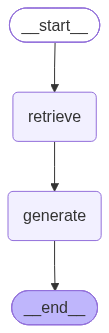

In [20]:
g = StateGraph(State)
g.add_node("retrieve", retrieve)
g.add_node("generate", generate)
g.add_edge(START, "retrieve")
g.add_edge("retrieve", "generate")
g.add_edge("generate", END)
app = g.compile()

app

In [21]:
# 5) Run within the books
res = app.invoke({"question": "Explain bias vs variance in machine learning? in 50 words.", "docs": [], "answer": ""})
print(res["answer"])

Bias refers to errors due to incorrect assumptions in the model, leading to underfitting. Variance measures the model's sensitivity to fluctuations in the training data, often resulting in overfitting. The bias-variance tradeoff is crucial for minimizing overall error in machine learning models.


In [24]:
res

{'question': 'Explain bias vs variance in machine learning? in 50 words.',
 'docs': [Document(id='d1811791-6e8a-4322-a3ed-71ebbb34f32f', metadata={'producer': 'Antenna House PDF Output Library 6.2.609 (Linux64)', 'creator': 'AH CSS Formatter V6.2 MR4 for Linux64 : 6.2.6.18551 (2014/09/24 15:00JST)', 'creationdate': '2017-03-10T21:55:34+00:00', 'author': 'Aurélien Géron', 'moddate': '2017-07-29T21:43:02+08:00', 'title': 'Hands-On Machine Learning with Scikit-Learn and TensorFlow', 'trapped': '/False', 'source': './documents/book3.pdf', 'total_pages': 564, 'page': 147, 'page_label': '126'}, page_content='10 This notion of bias is not to be confused with the bias term of linear models.\nFigure 4-16. Learning curves for the polynomial model\nOne way to improve an overfitting model is to feed it more training\nda\nta until the validation error reaches the training error.\nThe Bias/Variance Tradeoff\nAn importan\nt theoretical result of statistics and Machine Learning is the fact that a\nmod

In [35]:
# 5) Run the out of context of books 
res = app.invoke({"question": "What is a transformer in deep learning?", "docs": [], "answer": ""})
print(res["answer"])

The context does not provide a definition or explanation of a transformer in deep learning. Therefore, I don't know.


In [36]:
print(res['docs'][0].page_content)
print('*'*100)
print(res['docs'][1].page_content)
print('*'*100)
print(res['docs'][2].page_content)
print('*'*100)
print(res['docs'][3].page_content)

ducingrepresentationsthatareexpressedintermsofother,simplerrepresentations.
Deeplearningallowsthecomputertobuildcomplexconceptsoutofsimplercon-
cepts.Figureshowshowadeeplearningsystemcanrepresenttheconceptof1.2
animageofapersonbycombiningsimplerconcepts,suchascornersandcontours,
whichareinturndeﬁnedintermsofedges.
Thequintessentialexampleofadeeplearningmodelisthefeedforwarddeep
networkormultilayerperceptron(MLP).Amultilayerperceptronisjusta
mathematicalfunctionmappingsomesetofinputvaluestooutputvalues.The
functionisformedbycomposingmanysimplerfunctions.Wecanthinkofeach
applicationofadiﬀerentmathematicalfunctionasprovidinganewrepresentation
oftheinput.
Theideaoflearningtherightrepresentationforthedataprovidesoneperspec-
tiveondeeplearning.Anotherperspectiveondeeplearningisthatdepthallowsthe
computertolearnamulti-stepcomputerprogram.Eachlayeroftherepresentation
****************************************************************************************************
diﬀerentﬁlters.Iftheseﬁlter